# Unit 6 K-Means Clustering Tutorial
This notebook runs the supplied k-means demo, then Tasks A, B and C of the brief. I ran it in Google Colab.

## Scope and corrections
The original notebook is unchanged; I worked on a copy. I corrected the demo in five places. Its data file pointed to the author's own computer, so I load the same file from IBM's course storage. The demo scaled the data but then fitted k-means on the unscaled values; the model and the choice of k now use the scaled data. A fixed seed makes the clusters the same on every run. The 150 missing `Defaulted` values were silently set to 0; I count them first and keep the demo's choice. The 3D plot used a call that draws an empty figure in current matplotlib, so it now uses `add_subplot(projection='3d')`.

For the three tasks, I remove the label column before clustering and use it only afterwards, to see how far the clusters match it. I also test two choices that could change the answer: scaling (Tasks A and B) and how missing weather values are handled (Task C). Before running, upload `Unit06 iris.csv`, `Unit06 wine.csv` and `Unit06 weatherAUS.csv` to the Colab files pane (or place them beside this notebook).

In [1]:
from datetime import datetime, timezone
print("Run by Anne Dayer (student 39359) in Google Colab on",
      datetime.now(timezone.utc).strftime("%d %B %Y at %H:%M UTC"))

Run by Anne Dayer (student 39359) in Google Colab on 31 October 2026 at 15:11 UTC


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy, sklearn
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score
ROOT = Path.cwd()
OUT = ROOT / 'Unit6_ePortfolio_Exports'
OUT.mkdir(exist_ok=True)
SEED = 42
def source_file(name):
    for path in [ROOT / 'sources' / name, ROOT / name]:
        if path.exists():
            return path
    raise FileNotFoundError(f'Upload {name} to the Colab files pane or place it beside this notebook.')
def save_figure(name):
    plt.gcf().savefig(OUT / name, dpi=180, bbox_inches='tight')
versions = {name: mod.__version__ for name, mod in
            [('numpy', np), ('pandas', pd), ('scipy', scipy),
             ('sklearn', sklearn), ('matplotlib', matplotlib)]}
print('Package versions:', versions)

Package versions: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'sklearn': '1.6.1', 'matplotlib': '3.10.0'}


## Part 1: the supplied k-means demo, corrected

## Introduction

### Import libraries

In [3]:
import random
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

%matplotlib inline

# Customer Segmentation with K-Means
Imagine that you have a customer dataset, and you need to apply customer segmentation on this historical data.
Customer segmentation is the practice of partitioning a customer base into groups of individuals that have similar characteristics. It is a significant strategy as a business can target these specific groups of customers and effectively allocate marketing resources. For example, one group might contain customers who are high-profit and low-risk, that is, more likely to purchase products, or subscribe for a service. A business task is to retaining those customers. Another group might include customers from non-profit organizations. And so on.

### Load Data From CSV File
Before you can work with the data, you must use the URL to get the Cust_Segmentation.csv.

In [4]:
import pandas as pd
# The demo pointed to a file on the author's computer; this is the same file from IBM's course storage
cust_df = pd.read_csv("https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/ML0101ENv3/labs/Cust_Segmentation.csv")
cust_df.head()

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,Address,DebtIncomeRatio
0,1,41,2,6,19,0.124,1.073,0.0,NBA001,6.3
1,2,47,1,26,100,4.582,8.218,0.0,NBA021,12.8
2,3,33,2,10,57,6.111,5.802,1.0,NBA013,20.9
3,4,29,2,4,19,0.681,0.516,0.0,NBA009,6.3
4,5,47,1,31,253,9.308,8.908,0.0,NBA008,7.2


### Pre-processing

As you can see, __Address__ in this dataset is a categorical variable. k-means algorithm isn't directly applicable to categorical variables because Euclidean distance function isn't really meaningful for discrete variables. So, lets drop this feature and run clustering.

In [5]:
df = cust_df.drop('Address', axis=1)
df.head()

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio
0,1,41,2,6,19,0.124,1.073,0.0,6.3
1,2,47,1,26,100,4.582,8.218,0.0,12.8
2,3,33,2,10,57,6.111,5.802,1.0,20.9
3,4,29,2,4,19,0.681,0.516,0.0,6.3
4,5,47,1,31,253,9.308,8.908,0.0,7.2


#### Normalizing over the standard deviation
Now let's normalize the dataset. But why do we need normalization in the first place? Normalization is a statistical method that helps mathematical-based algorithms to interpret features with different magnitudes and distributions equally. We use __standardScaler()__ to normalize our dataset.

In [6]:
from sklearn.preprocessing import StandardScaler
# Count the missing values before replacing them, rather than replacing them silently.
# Filling them with 0 treats an unknown default status as "not defaulted": a teaching assumption only.
print('Missing values per column:', df.isna().sum()[df.isna().sum() > 0].to_dict())
X = df.values[:,1:]
X = np.nan_to_num(X)
Clus_dataSet = StandardScaler().fit_transform(X)
Clus_dataSet

Missing values per column: {'Defaulted': 150}


array([[ 0.74291541,  0.31212243, -0.37878978, ..., -0.59048916,
        -0.52379654, -0.57652509],
       [ 1.48949049, -0.76634938,  2.5737211 , ...,  1.51296181,
        -0.52379654,  0.39138677],
       [-0.25251804,  0.31212243,  0.2117124 , ...,  0.80170393,
         1.90913822,  1.59755385],
       ...,
       [-1.24795149,  2.46906604, -1.26454304, ...,  0.03863257,
         1.90913822,  3.45892281],
       [-0.37694723, -0.76634938,  0.50696349, ..., -0.70147601,
        -0.52379654, -1.08281745],
       [ 2.1116364 , -0.76634938,  1.09746566, ...,  0.16463355,
        -0.52379654, -0.2340332 ]])

### Modeling

In our example (if we didn't have access to the k-means algorithm), it would be the same as guessing that each customer group would have certain age, income, education, etc, with multiple tests and experiments. However, using the K-means clustering we can do all this process much easier.

Lets apply k-means on our dataset, and take look at cluster labels.

In [7]:
from sklearn.cluster import KMeans
clusterNum = 3
k_means = KMeans(init = "k-means++", n_clusters = clusterNum, n_init = 12, random_state = SEED)  # Fixed seed so the clusters are the same on every run
k_means.fit(Clus_dataSet)  # Fit on the scaled data, not the raw values
labels = k_means.labels_
print(labels)

[2 0 1 2 0 0 2 2 2 0 1 2 2 2 1 2 2 2 0 2 2 2 1 0 0 2 2 2 2 2 2 0 1 2 2 2 1
 1 2 0 1 0 2 0 2 0 2 2 2 2 0 0 1 2 1 1 1 2 2 2 0 2 0 0 2 2 2 1 2 1 2 2 2 2
 2 2 2 2 0 2 2 1 0 2 0 2 2 2 1 1 2 2 1 1 2 2 2 2 1 2 1 0 2 1 1 0 2 2 2 2 2
 2 2 1 2 2 2 2 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 1 1 2 2 2 0 2 2 1
 2 2 2 0 1 2 2 2 2 0 1 1 2 0 2 2 2 2 2 2 2 2 0 2 2 1 2 1 2 2 1 0 1 2 2 0 1
 0 2 2 2 2 2 0 2 1 2 2 2 0 0 2 0 2 1 2 2 1 2 0 2 1 2 2 2 2 2 1 1 0 2 2 1 0
 2 2 2 2 0 2 2 1 2 2 2 2 0 2 2 1 0 2 2 2 2 2 2 0 2 0 2 2 2 2 2 2 0 1 2 1 2
 2 2 0 2 1 0 1 2 0 2 2 1 2 2 2 2 1 1 1 2 2 2 0 2 2 0 2 0 2 2 0 2 2 2 1 2 2
 1 2 1 0 2 2 2 2 1 2 2 1 1 2 2 2 2 2 2 2 2 1 2 1 0 2 1 2 2 2 1 1 2 2 2 0 1
 2 2 1 2 0 2 2 2 2 2 1 0 2 2 2 2 2 0 2 2 2 2 2 0 2 2 2 0 1 2 1 2 2 2 0 0 2
 1 2 0 1 1 2 2 2 1 2 2 2 2 2 0 2 0 2 2 2 2 1 2 1 2 2 2 0 2 2 2 2 1 2 2 1 1
 0 2 2 2 2 2 1 1 2 0 1 0 2 2 1 2 2 0 0 2 1 2 2 0 2 1 2 0 2 2 2 0 2 2 2 2 0
 2 1 2 2 2 2 0 1 2 2 0 2 1 2 2 0 2 0 2 2 2 2 2 2 2 0 0 2 2 0 2 1 2 2 2 1 2
 1 2 2 2 2 2 0 1 1 2 0 2 

### Insights
We assign the labels to each row in dataframe.

In [8]:
df["Clus_km"] = labels
df.head(5)

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio,Clus_km
0,1,41,2,6,19,0.124,1.073,0.0,6.3,2
1,2,47,1,26,100,4.582,8.218,0.0,12.8,0
2,3,33,2,10,57,6.111,5.802,1.0,20.9,1
3,4,29,2,4,19,0.681,0.516,0.0,6.3,2
4,5,47,1,31,253,9.308,8.908,0.0,7.2,0


We can easily check the centroid values by averaging the features in each cluster.

In [9]:
df.groupby('Clus_km').mean()

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio
Clus_km,,,,,,,,,
0,424.408163,43.000000,1.931973,17.197279,101.959184,4.220673,7.954483,0.162393,13.915646
1,424.451807,31.891566,1.861446,3.963855,31.789157,1.576675,2.843355,0.993939,13.994578
2,426.122905,33.817505,1.603352,7.625698,36.143389,0.853128,1.816855,0.000000,7.964991


Now, lets look at the distribution of customers based on their age and income:

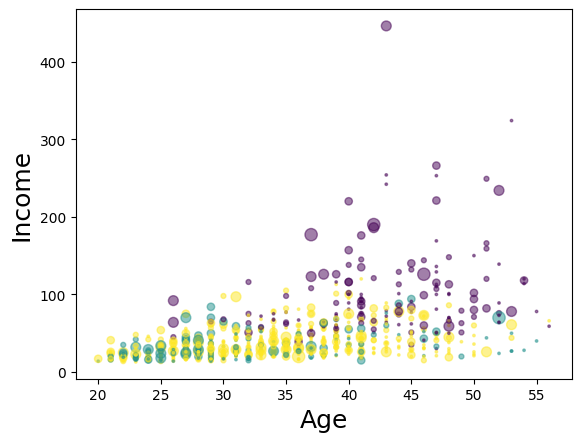

In [10]:
area = np.pi * ( X[:, 1])**2
plt.scatter(X[:, 0], X[:, 3], s=area, c=labels.astype(np.float64), alpha=0.5)
plt.xlabel('Age', fontsize=18)
plt.ylabel('Income', fontsize=18)

plt.show()

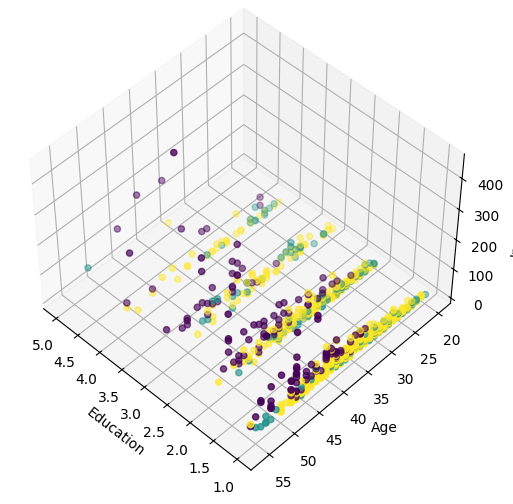

In [11]:
from mpl_toolkits.mplot3d import Axes3D
fig = plt.figure(1, figsize=(8, 6))
plt.clf()
ax = fig.add_subplot(projection='3d', elev=48, azim=134)  # Axes3D(fig, rect=...) draws an empty figure in current matplotlib

plt.cla()
ax.set_xlabel('Education')
ax.set_ylabel('Age')
ax.set_zlabel('Income')

ax.scatter(X[:, 1], X[:, 0], X[:, 3], c= labels.astype(np.float64))
plt.show()

#### setting value for k

In [12]:
sse = []
for k in range(1, 10):
    kmeans = KMeans(n_clusters=k, init= "k-means++",n_init= 12,max_iter= 300, random_state=SEED)
    kmeans.fit(Clus_dataSet)
    sse.append(kmeans.inertia_)

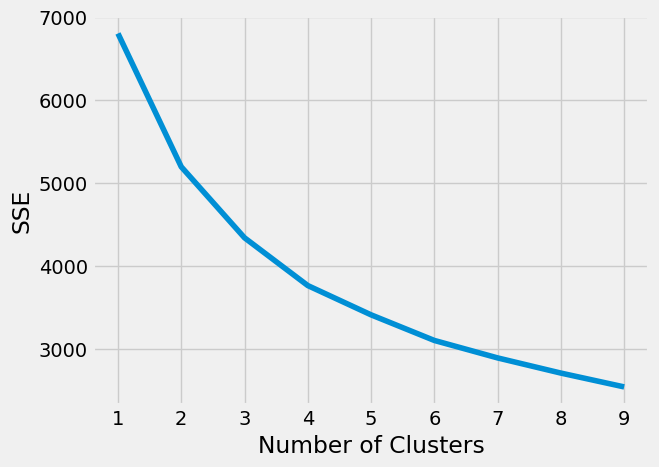

In [13]:
plt.style.use("fivethirtyeight")
plt.plot(range(1, 10), sse)
plt.xticks(range(1, 10))
plt.xlabel("Number of Clusters")
plt.ylabel("SSE")
plt.show()

In [14]:
from sklearn.metrics import silhouette_score, silhouette_samples

silhouette_coefficients = []
# Notice you start at 2 clusters for silhouette coefficient
for k in range(2, 10):
    kmeans = KMeans(n_clusters=k, init= "k-means++",n_init= 12,max_iter= 300, random_state=SEED)
    kmeans.fit(Clus_dataSet)
    score = silhouette_score(Clus_dataSet, kmeans.labels_)
    silhouette_coefficients.append(score)

silhouette_coefficients

[np.float64(0.3395638268481061),
 np.float64(0.28738683325129355),
 np.float64(0.249434089974843),
 np.float64(0.2496481795475487),
 np.float64(0.24461829828791243),
 np.float64(0.21763930519440097),
 np.float64(0.20450000037797936),
 np.float64(0.19533120814786675)]

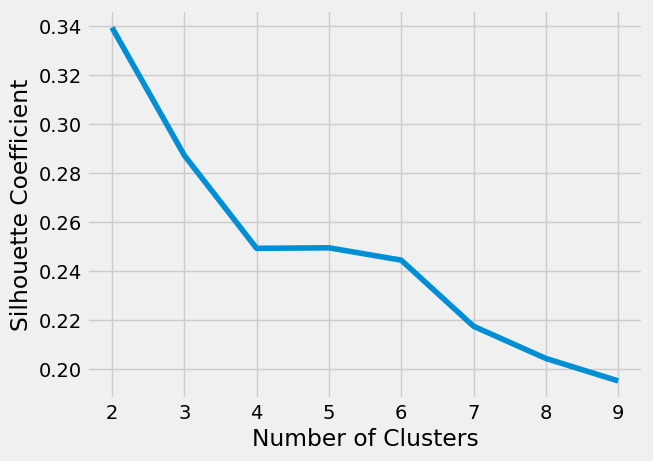

In [15]:
plt.style.use("fivethirtyeight")
plt.plot(range(2, 10), silhouette_coefficients)
plt.xticks(range(2, 10))
plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Coefficient")
plt.show()
plt.style.use("default")  # Return to the default style for the tasks below

## Part 2: helper functions for the tasks
`scan_k` fits k-means for each k and records the SSE (the demo's elbow measure) and the silhouette score. `compare_with_labels` compares clusters with the true labels. Cluster numbers are arbitrary, so it pairs each cluster with the label it overlaps most, one to one, before counting matches. The adjusted Rand index (ARI; Hubert and Arabie, 1985, cited in Arabie and Hubert, 1992) gives 1 for a perfect match and about 0 for a random one.

In [16]:
fitted = {}  # Models kept from each scan, so they are not fitted twice

def scan_k(data, k_values, sample_size=None, keep=None):
    rows = []
    for k in k_values:
        model = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(data)
        if keep:
            fitted[(keep, k)] = model
        sil = silhouette_score(data, model.labels_, sample_size=sample_size, random_state=SEED)
        rows.append({'k': k, 'sse': model.inertia_, 'silhouette': sil})
    return pd.DataFrame(rows)

def compare_with_labels(true_labels, clusters):
    table = pd.crosstab(pd.Series(true_labels, name='label'), pd.Series(clusters, name='cluster'))
    rows, cols = linear_sum_assignment(-table.to_numpy())
    matched = int(table.to_numpy()[rows, cols].sum())
    pairing = {int(table.columns[c]): table.index[r] for r, c in zip(rows, cols)}
    return {'table': table, 'pairing': pairing, 'matched': matched,
            'share_matched': matched / len(true_labels),
            'ari': adjusted_rand_score(true_labels, clusters)}

def plot_scan(scan, title, name):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
    ax[0].plot(scan.k, scan.sse, marker='o'); ax[0].set(xlabel='k', ylabel='SSE', title=f'{title}: SSE')
    ax[1].plot(scan.k, scan.silhouette, marker='o'); ax[1].set(xlabel='k', ylabel='Silhouette', title=f'{title}: silhouette')
    fig.tight_layout(); save_figure(name); plt.show()

## Part 3: Task A, iris data
I use the raw measurements as a baseline and compare two kinds of scaling: z-scores (`StandardScaler`) and dividing by the range (`MinMaxScaler`). The `species` column is removed before clustering.

(150, 5)
{'setosa': 50, 'versicolor': 50, 'virginica': 50}


,k,sse,silhouette
0,2,152.369,0.681
1,3,78.941,0.553
2,4,57.318,0.498
3,5,46.536,0.489
4,6,38.931,0.368
5,7,34.360,0.355
6,8,30.023,0.352


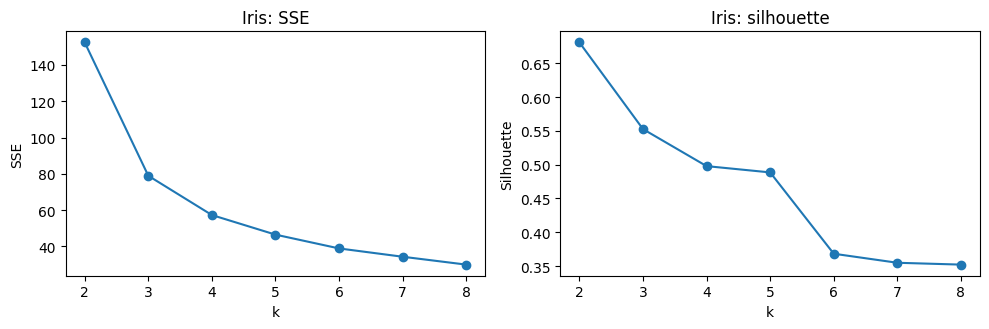

In [17]:
iris = pd.read_csv(source_file('Unit06 iris.csv'))
print(iris.shape); print(iris.species.value_counts().to_dict())
iris_X = iris.drop(columns='species')
iris_scan = scan_k(iris_X, range(2, 9))
display(iris_scan.round(3))
plot_scan(iris_scan, 'Iris', '01_iris_choice_of_k.png')

In [18]:
iris_model = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(iris_X)
iris_result = compare_with_labels(iris.species, iris_model.labels_)
display(iris_result['table'])
print(f"Matched: {iris_result['matched']} of {len(iris)} ({iris_result['share_matched']:.1%}); ARI {iris_result['ari']:.3f}")
iris_scaled_X = StandardScaler().fit_transform(iris_X)
iris_scaled = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(iris_scaled_X)
iris_scaled_result = compare_with_labels(iris.species, iris_scaled.labels_)
print(f"Scaled comparison: matched {iris_scaled_result['matched']} of {len(iris)} ({iris_scaled_result['share_matched']:.1%}); ARI {iris_scaled_result['ari']:.3f}")
print(f"Silhouette at k = 3: raw {silhouette_score(iris_X, iris_model.labels_):.3f}; scaled {silhouette_score(iris_scaled_X, iris_scaled.labels_):.3f}")
# Range scaling: divide each measurement by its range (0 to 1), the alternative to z-scores
iris_range_X = MinMaxScaler().fit_transform(iris_X)
iris_range = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(iris_range_X)
iris_range_result = compare_with_labels(iris.species, iris_range.labels_)
print(f"Range-scaled comparison: matched {iris_range_result['matched']} of {len(iris)} ({iris_range_result['share_matched']:.1%}); ARI {iris_range_result['ari']:.3f}; silhouette {silhouette_score(iris_range_X, iris_range.labels_):.3f}")

cluster,0,1,2
label,,,
setosa,0,50,0
versicolor,48,0,2
virginica,14,0,36


Matched: 134 of 150 (89.3%); ARI 0.730
Scaled comparison: matched 125 of 150 (83.3%); ARI 0.620
Silhouette at k = 3: raw 0.553; scaled 0.459
Range-scaled comparison: matched 133 of 150 (88.7%); ARI 0.716; silhouette 0.504


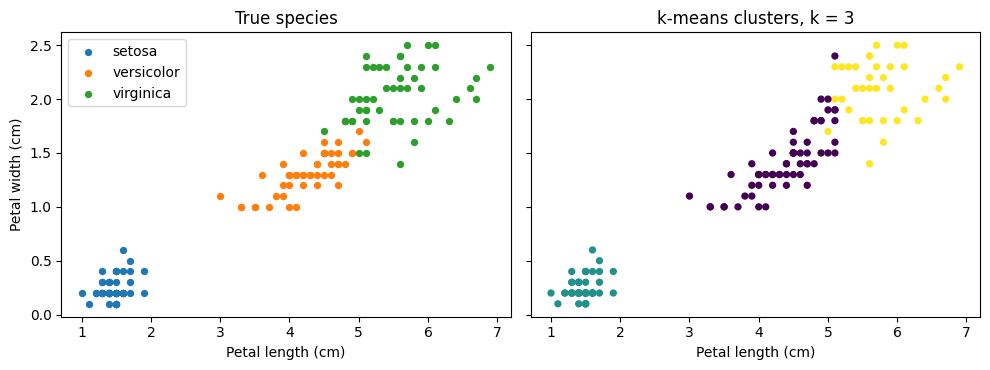

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, sharey=True)
for name, colour in zip(sorted(iris.species.unique()), ['tab:blue', 'tab:orange', 'tab:green']):
    part = iris[iris.species == name]
    ax[0].scatter(part.petal_length, part.petal_width, s=18, color=colour, label=name)
ax[0].set(title='True species', xlabel='Petal length (cm)', ylabel='Petal width (cm)'); ax[0].legend()
ax[1].scatter(iris.petal_length, iris.petal_width, s=18, c=iris_model.labels_, cmap='viridis')
ax[1].set(title='k-means clusters, k = 3', xlabel='Petal length (cm)')
fig.tight_layout(); save_figure('02_iris_species_and_clusters.png'); plt.show()

## Part 4: Task B, wine data
The 13 chemical measurements use very different units and spreads. What matters for Euclidean distance is how much each measurement varies, not its size: proline varies by hundreds while hue varies by tenths, so without scaling proline would dominate the distances. I compare raw clustering with z-score and range scaling. The `Wine` column (the cultivar, 1 to 3) is removed before clustering.

(178, 14)
{1: 59, 2: 71, 3: 48}


,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


Proline's share of the total raw variance: 99.77%


,k,sse,silhouette
0,2,1658.759,0.259
1,3,1277.928,0.285
2,4,1175.428,0.260
3,5,1109.513,0.202
4,6,1046.002,0.237
5,7,981.595,0.204
6,8,935.201,0.157


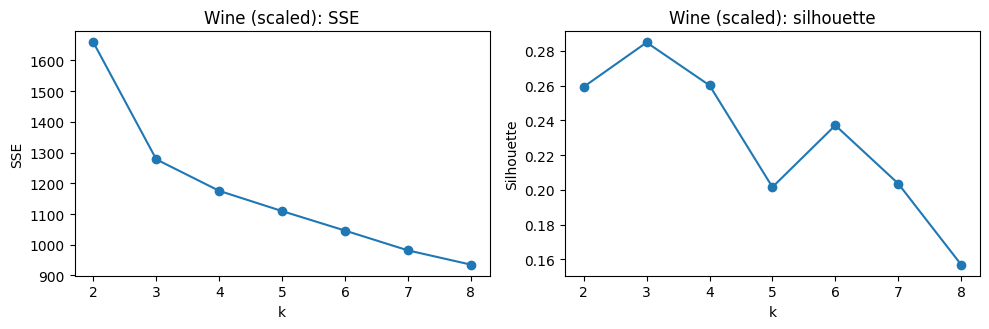

In [20]:
wine = pd.read_csv(source_file('Unit06 wine.csv'))
print(wine.shape); print(wine.Wine.value_counts().sort_index().to_dict())
wine_X = wine.drop(columns='Wine')
display(wine_X.describe().loc[['mean', 'std', 'min', 'max']].round(2))
print(f"Proline's share of the total raw variance: {wine_X.var()['Proline'] / wine_X.var().sum():.2%}")
wine_scaled = StandardScaler().fit_transform(wine_X)
wine_scan = scan_k(wine_scaled, range(2, 9))
display(wine_scan.round(3))
plot_scan(wine_scan, 'Wine (scaled)', '03_wine_choice_of_k.png')

In [21]:
wine_raw_model = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(wine_X)
wine_model = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(wine_scaled)
wine_raw_result = compare_with_labels(wine.Wine, wine_raw_model.labels_)
wine_result = compare_with_labels(wine.Wine, wine_model.labels_)
print(f"Raw values: matched {wine_raw_result['share_matched']:.1%}; ARI {wine_raw_result['ari']:.3f}")
print(f"Scaled values: matched {wine_result['matched']} of {len(wine)} ({wine_result['share_matched']:.1%}); ARI {wine_result['ari']:.3f}")
print(f"Silhouette at k = 3: raw {silhouette_score(wine_X, wine_raw_model.labels_):.3f}; scaled {silhouette_score(wine_scaled, wine_model.labels_):.3f}")
wine_range_X = MinMaxScaler().fit_transform(wine_X)
wine_range = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(wine_range_X)
wine_range_result = compare_with_labels(wine.Wine, wine_range.labels_)
print(f"Range-scaled values: matched {wine_range_result['matched']} of {len(wine)} ({wine_range_result['share_matched']:.1%}); ARI {wine_range_result['ari']:.3f}; silhouette {silhouette_score(wine_range_X, wine_range.labels_):.3f}")
display(wine_result['table'])

Raw values: matched 70.2%; ARI 0.371
Scaled values: matched 172 of 178 (96.6%); ARI 0.897
Silhouette at k = 3: raw 0.571; scaled 0.285
Range-scaled values: matched 169 of 178 (94.9%); ARI 0.854; silhouette 0.301


cluster,0,1,2
label,,,
1,0,0,59
2,65,3,3
3,0,48,0


Share of variation shown by the two components: 55.4%


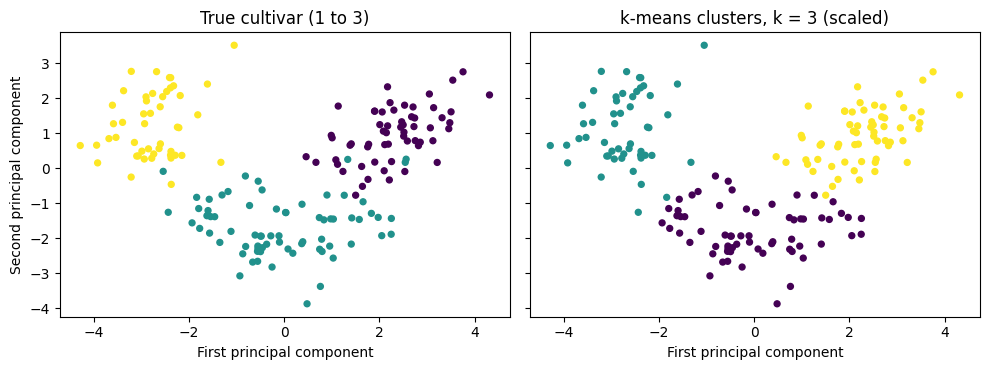

In [22]:
wine_pca = PCA(n_components=2, random_state=SEED).fit(wine_scaled)
wine_2d = wine_pca.transform(wine_scaled)
print(f"Share of variation shown by the two components: {wine_pca.explained_variance_ratio_.sum():.1%}")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, sharey=True)
ax[0].scatter(wine_2d[:, 0], wine_2d[:, 1], s=18, c=wine.Wine, cmap='viridis')
ax[0].set(title='True cultivar (1 to 3)', xlabel='First principal component', ylabel='Second principal component')
ax[1].scatter(wine_2d[:, 0], wine_2d[:, 1], s=18, c=wine_model.labels_, cmap='viridis')
ax[1].set(title='k-means clusters, k = 3 (scaled)', xlabel='First principal component')
fig.tight_layout(); save_figure('04_wine_cultivars_and_clusters.png'); plt.show()

## Part 5: Task C, weatherAUS data
The supplied file has 12 numeric weather measurements plus RainToday and RainTomorrow (Yes or No). I remove the two rain columns, because Euclidean distance needs numbers, and keep them only to describe the clusters afterwards. Rows with any missing measurement are removed, and a later cell checks that choice against filling the gaps instead. I standardise the measurements because their units and spreads differ; otherwise the most variable ones would dominate the squared distances. With over 100,000 rows, the silhouette score is computed on a random sample of 10,000.

Rows supplied: 145460
Missing values per column: {'MinTemp': 1485, 'MaxTemp': 1261, 'Rainfall': 3261, 'WindGustSpeed': 10263, 'WindSpeed9am': 1767, 'WindSpeed3pm': 3062, 'Humidity9am': 2654, 'Humidity3pm': 4507, 'Pressure9am': 15065, 'Pressure3pm': 15028, 'Temp9am': 1767, 'Temp3pm': 3609}
Rows with every measurement: 120381 (82.8%)


,k,sse,silhouette
0,2,1069603.685,0.237
1,3,911738.967,0.229
2,4,829797.320,0.160
3,5,764248.498,0.172
4,6,703918.790,0.168


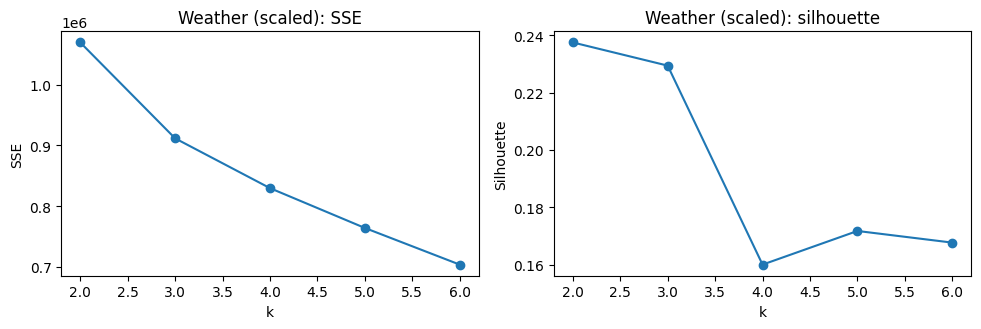

In [23]:
weather = pd.read_csv(source_file('Unit06 weatherAUS.csv'))
numeric = weather.columns.drop(['RainToday', 'RainTomorrow'])
print('Rows supplied:', len(weather))
print('Missing values per column:', weather[numeric].isna().sum().to_dict())
weather_complete = weather.dropna(subset=numeric).reset_index(drop=True)
print('Rows with every measurement:', len(weather_complete), f'({len(weather_complete)/len(weather):.1%})')
weather_scaled = StandardScaler().fit_transform(weather_complete[numeric])
weather_scan = scan_k(weather_scaled, range(2, 7), sample_size=10000, keep='weather')
display(weather_scan.round(3))
plot_scan(weather_scan, 'Weather (scaled)', '05_weather_choice_of_k.png')

Share of variation shown by the two components: [0.395 0.207] 0.603


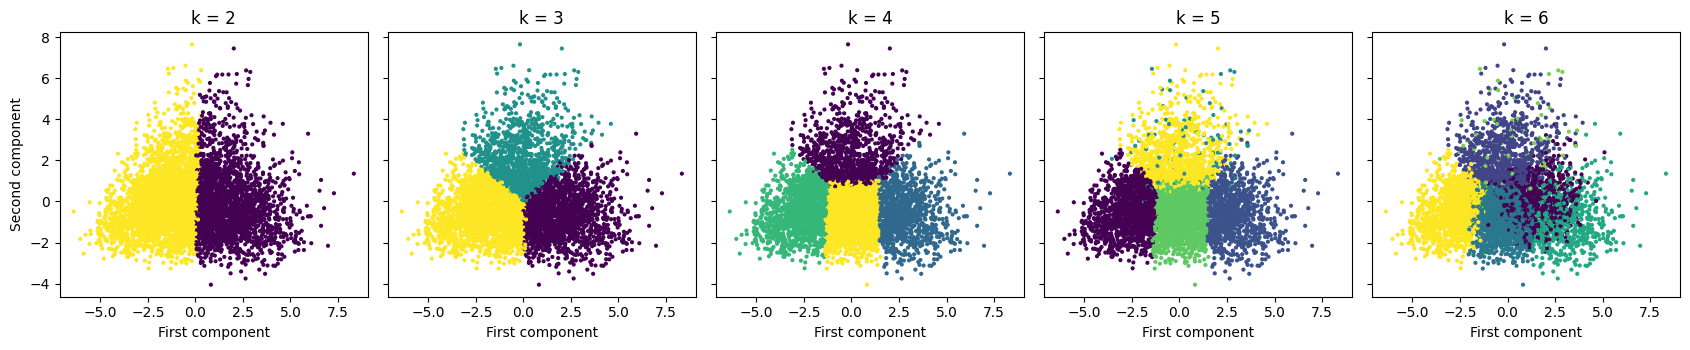

In [24]:
weather_pca = PCA(n_components=2, random_state=SEED).fit(weather_scaled)
weather_2d = weather_pca.transform(weather_scaled)
print('Share of variation shown by the two components:', weather_pca.explained_variance_ratio_.round(3), round(weather_pca.explained_variance_ratio_.sum(), 3))
plot_rows = np.random.default_rng(SEED).choice(len(weather_2d), 5000, replace=False)
weather_models = {}
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6), sharex=True, sharey=True)
for ax, k in zip(axes, range(2, 7)):
    weather_models[k] = fitted[('weather', k)]  # Reuse the model fitted in the scan above
    ax.scatter(weather_2d[plot_rows, 0], weather_2d[plot_rows, 1], s=4, c=weather_models[k].labels_[plot_rows], cmap='viridis')
    ax.set(title=f'k = {k}', xlabel='First component')
axes[0].set_ylabel('Second component')
fig.tight_layout(); save_figure('06_weather_clusters_k2_to_k6.png'); plt.show()

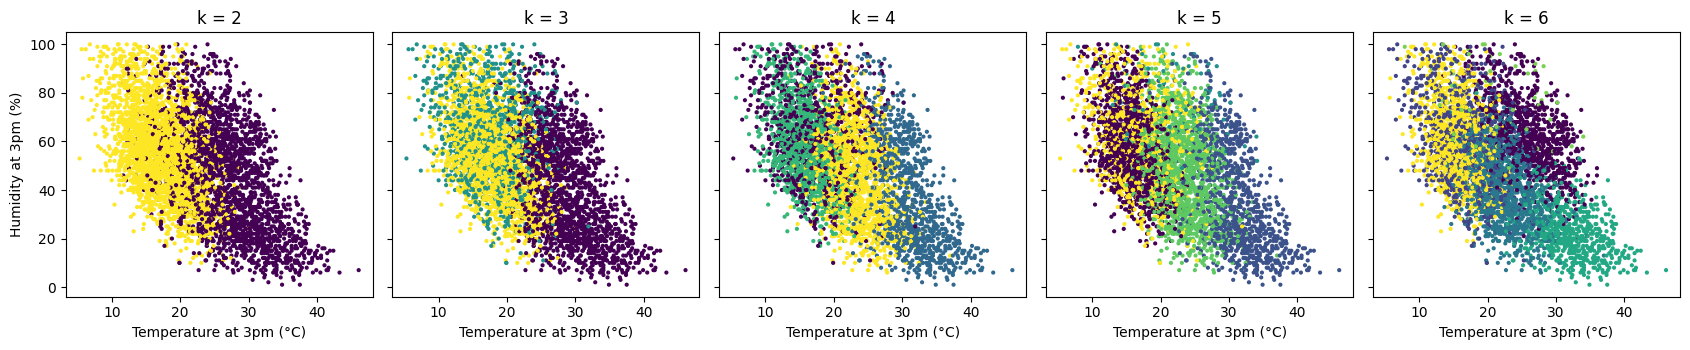

In [25]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6), sharex=True, sharey=True)
for ax, k in zip(axes, range(2, 7)):
    ax.scatter(weather_complete.Temp3pm.iloc[plot_rows], weather_complete.Humidity3pm.iloc[plot_rows],
               s=4, c=weather_models[k].labels_[plot_rows], cmap='viridis')
    ax.set(title=f'k = {k}', xlabel='Temperature at 3pm (°C)')
axes[0].set_ylabel('Humidity at 3pm (%)')
fig.tight_layout(); save_figure('07_weather_temperature_humidity.png'); plt.show()

In [26]:
# Describe the k = 2 clusters with their average measurements and the share of rainy days
k2 = weather_complete.assign(cluster=weather_models[2].labels_)
profile = k2.groupby('cluster')[numeric].mean().round(1)
profile['rows'] = k2.cluster.value_counts().sort_index()
# Blank rain values are left out of the shares
profile['rain_today_share'] = k2.groupby('cluster').RainToday.apply(lambda s: s.dropna().eq('Yes').mean()).round(3)
profile['rain_tomorrow_share'] = k2.groupby('cluster').RainTomorrow.apply(lambda s: s.dropna().eq('Yes').mean()).round(3)
display(profile.T)

cluster,0,1
MinTemp,16.900,8.300
MaxTemp,28.900,18.500
Rainfall,2.400,2.300
WindGustSpeed,44.300,36.300
WindSpeed9am,16.400,12.500
WindSpeed3pm,21.400,17.000
Humidity9am,59.600,76.300
Humidity3pm,44.500,56.700
Pressure9am,1013.900,1021.100
Pressure3pm,1011.200,1018.900


### Sensitivity check: filling the gaps instead of dropping rows
Dropping incomplete rows removed 17.2% of the data. Here I keep every row with at least one measurement, fill each gap with that column's median, and repeat the scan. Then I compare the two k = 3 results on the rows both versions contain.

In [27]:
weather_partial = weather[weather[numeric].notna().any(axis=1)].copy()
gaps_filled = int(weather_partial[numeric].isna().sum().sum())
weather_partial[numeric] = weather_partial[numeric].fillna(weather_partial[numeric].median())
print('Rows kept:', len(weather_partial), '| rows with no measurement at all:', len(weather) - len(weather_partial), '| gaps filled with the median:', gaps_filled)
filled_scaled = StandardScaler().fit_transform(weather_partial[numeric])
filled_scan = scan_k(filled_scaled, range(2, 7), sample_size=10000, keep='filled')
display(pd.DataFrame({'k': weather_scan.k, 'silhouette, rows dropped': weather_scan.silhouette.round(3),
                      'silhouette, gaps filled': filled_scan.silhouette.round(3)}))
# Compare the two k = 3 results on the rows that had every measurement
complete_mask = weather_partial[numeric].index.isin(weather.dropna(subset=numeric).index)
shared_ari = adjusted_rand_score(fitted[('weather', 3)].labels_, fitted[('filled', 3)].labels_[complete_mask])
print(f'k = 3 agreement between the two versions on the {complete_mask.sum()} shared rows: ARI {shared_ari:.3f}')

Rows kept: 145207 | rows with no measurement at all: 253 | gaps filled with the median: 60693


,k,"silhouette, rows dropped","silhouette, gaps filled"
0,2,0.237,0.226
1,3,0.229,0.218
2,4,0.160,0.154
3,5,0.172,0.165
4,6,0.168,0.156


k = 3 agreement between the two versions on the 120381 shared rows: ARI 0.968


In [28]:
metrics = {'run_by': 'Anne Dayer (student 39359)',
    'run_at_utc': datetime.now(timezone.utc).isoformat(timespec='minutes'),
    'execution_scope': 'Google Colab', 'packages': versions,
    'demo': {'rows': len(cust_df), 'missing_defaulted': int(cust_df.Defaulted.isna().sum()),
             'cluster_sizes': pd.Series(labels).value_counts().sort_index().tolist()},
    'iris': {'scan': iris_scan.to_dict('records'), 'matched': iris_result['matched'],
             'share_matched': iris_result['share_matched'], 'ari': iris_result['ari'],
             'scaled_share_matched': iris_scaled_result['share_matched'], 'scaled_ari': iris_scaled_result['ari'],
             'range_share_matched': iris_range_result['share_matched'], 'range_ari': iris_range_result['ari'],
             'table': iris_result['table'].to_dict()},
    'wine': {'scan': wine_scan.to_dict('records'), 'matched': wine_result['matched'],
             'share_matched': wine_result['share_matched'], 'ari': wine_result['ari'],
             'raw_share_matched': wine_raw_result['share_matched'], 'raw_ari': wine_raw_result['ari'],
             'range_share_matched': wine_range_result['share_matched'], 'range_ari': wine_range_result['ari'],
             'table': {str(k): v for k, v in wine_result['table'].to_dict().items()}},
    'weather': {'rows_supplied': len(weather), 'rows_complete': len(weather_complete),
                'scan': weather_scan.to_dict('records'),
                'pca_variance': weather_pca.explained_variance_ratio_.tolist(),
                'filled_rows': len(weather_partial), 'gaps_filled': gaps_filled,
                'filled_scan': filled_scan.to_dict('records'), 'k3_shared_ari': shared_ari,
                'k2_profile': profile.reset_index().to_dict('records')}}
(OUT / 'Unit6_metrics.json').write_text(json.dumps(metrics, indent=2, default=str), encoding='utf-8')
print('Outputs saved to', OUT)

Outputs saved to /content/Unit6_ePortfolio_Exports


## Interpretation and limitations
K-means always returns the number of groups it is asked for, so a tidy result is not proof that the groups exist. The labels in Tasks A and B are used only after clustering, to check the result, so matching them is agreement after fitting, not prediction accuracy; in real use there would be no labels to check against. Scaling is a choice with consequences. Géron (2025) advises scaling before k-means because it generally helps; here z-scores helped wine a great deal but lowered the iris match. Dividing by the range, which Milligan and Cooper (1988, cited in Arabie and Hubert, 1992) found worked better, came close to the best result on both. A higher silhouette score did not mean a better match with the labels either: for wine, the raw clusters scored higher but matched far worse. Without location or date columns, the weather clusters cannot be interpreted by station or season. Dropping incomplete rows may change which days are represented, and this file cannot show whether some stations lose more rows than others. The scatter plots show only two dimensions of twelve, so they cannot prove whether clusters are separate in the full data. Filling the missing demo values with 0 treats an unknown default status as no default, which would need justifying before any real customer decision.

## Sources
- Aeberhard, S. and Forina, M. (1992) *Wine* [Dataset]. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C5PC7J
- Arabie, P. and Hubert, L.J. (1992) 'Combinatorial data analysis', *Annual Review of Psychology*, 43, pp. 169–203. Available at: https://doi.org/10.1146/annurev.ps.43.020192.001125
- Fisher, R.A. (1936) *Iris* [Dataset]. UCI Machine Learning Repository. Available at: https://doi.org/10.24432/C56C76
- Géron, A. (2025) *Hands-On Machine Learning with Scikit-Learn and PyTorch*. Santa Rosa: O’Reilly.
- IBM (no date) *Customer Segmentation Teaching Dataset* [Dataset]. Available at: https://s3-api.us-geo.objectstorage.softlayer.net/cf-courses-data/CognitiveClass/ML0101ENv3/labs/Cust_Segmentation.csv (Accessed: 31 October 2026).
- Rousseeuw, P.J. (1987) 'Silhouettes: a graphical aid to the interpretation and validation of cluster analysis', *Journal of Computational and Applied Mathematics*, 20, pp. 53–65. Available at: https://doi.org/10.1016/0377-0427(87)90125-7
- Young, J. (2020) *Rain in Australia* [Dataset]. Kaggle. Observations from the Australian Bureau of Meteorology. Available at: https://www.kaggle.com/datasets/jsphyg/weather-dataset-rattle-package (Accessed: 31 October 2026).

Supplied materials: University of Essex Unit 6 Seminar brief, K-Means demo notebook, Unit06 iris.csv, Unit06 wine.csv and Unit06 weatherAUS.csv.